
聚类评估指标（5个簇）
轮廓系数(Silhouette): 0.0360
Calinski-Harabasz指数: 12.7646
簇分布: {np.int32(0): np.int64(59), np.int32(1): np.int64(101), np.int32(2): np.int64(281), np.int32(3): np.int64(59), np.int32(4): np.int64(140)}


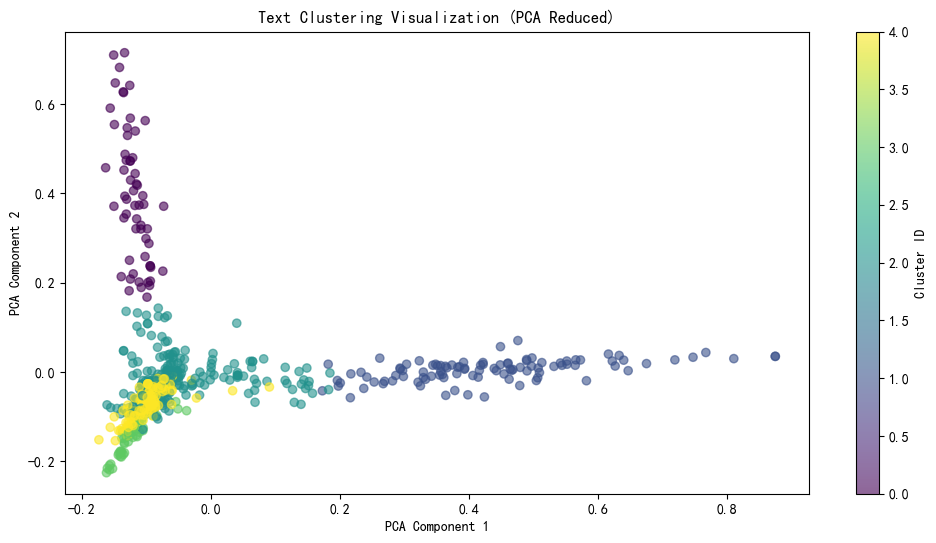

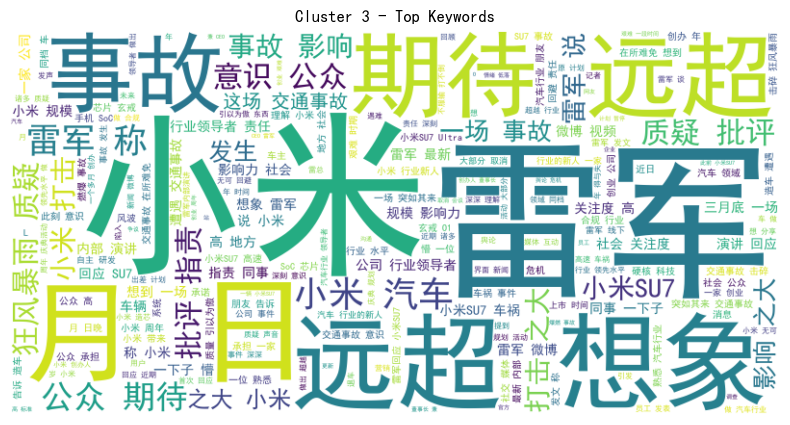

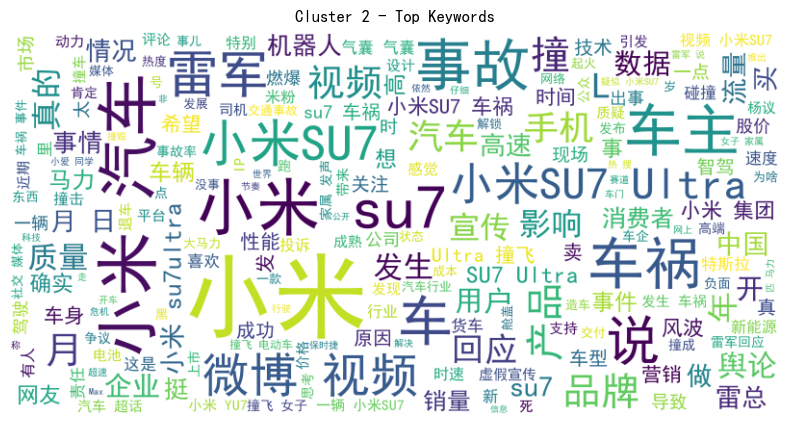

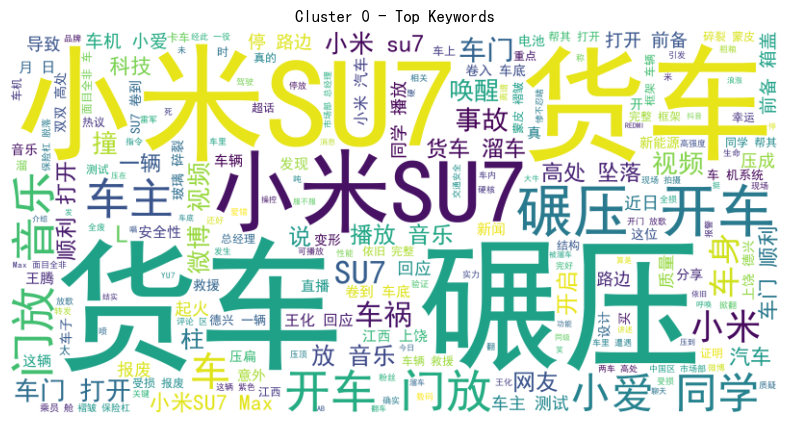

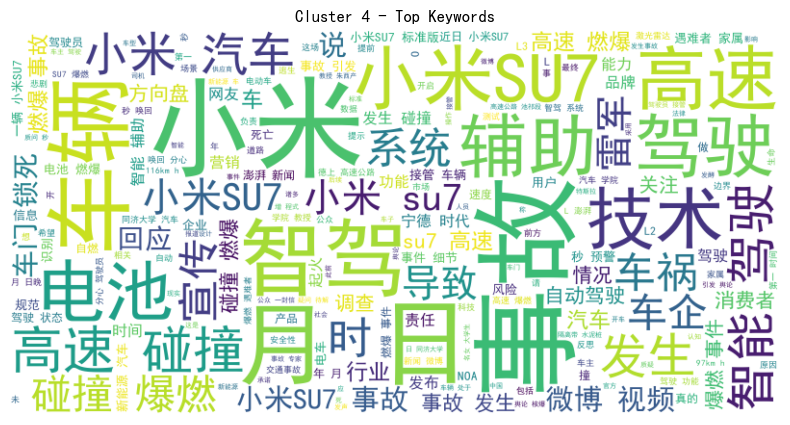

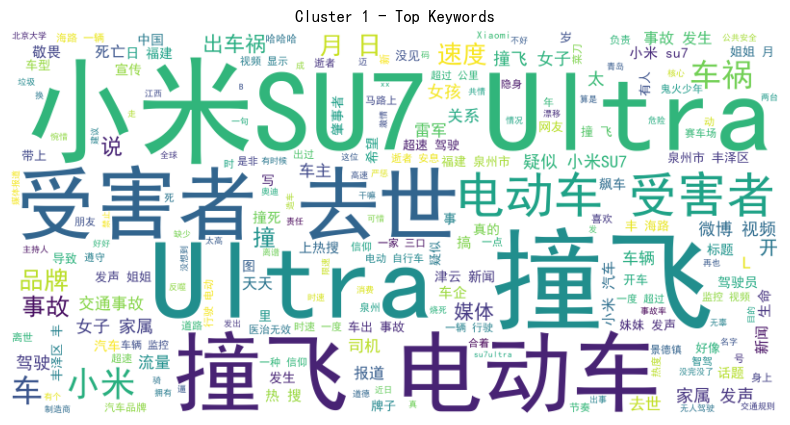

c:\Users\86182\anaconda3\envs\learn\Lib\site-packages\xgboost\training.py:183: UserWarning: [01:25:18] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\86182\anaconda3\envs\learn\Lib\site-packages\xgboost\training.py:183: UserWarning: [01:25:19] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\86182\anaconda3\envs\learn\Lib\site-packages\xgboost\training.py:183: UserWarning: [01:25:21] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\86182\anaconda3\envs\learn\Lib\site-packages\xgboost\training.py:183: UserWarning: [01:25:22] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_labe


分类器性能评估(5折交叉验证均值):
SVM 准确率: 0.8797 | F1-score: 0.8703
XGBoost 准确率: 0.8984 | F1-score: 0.8973


c:\Users\86182\anaconda3\envs\learn\Lib\site-packages\xgboost\training.py:183: UserWarning: [01:25:25] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


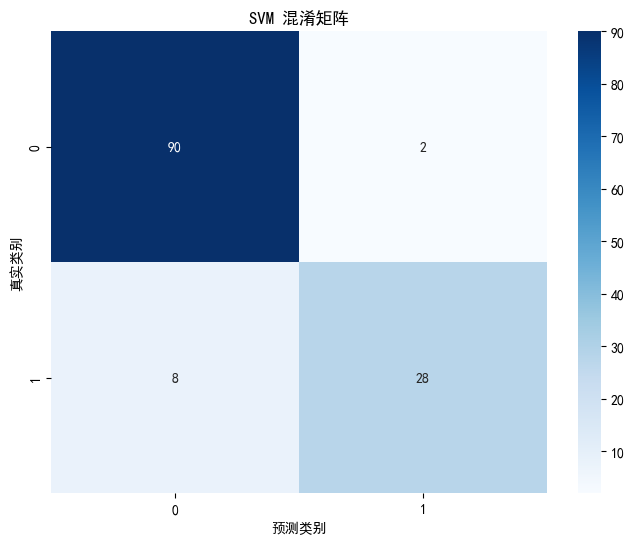

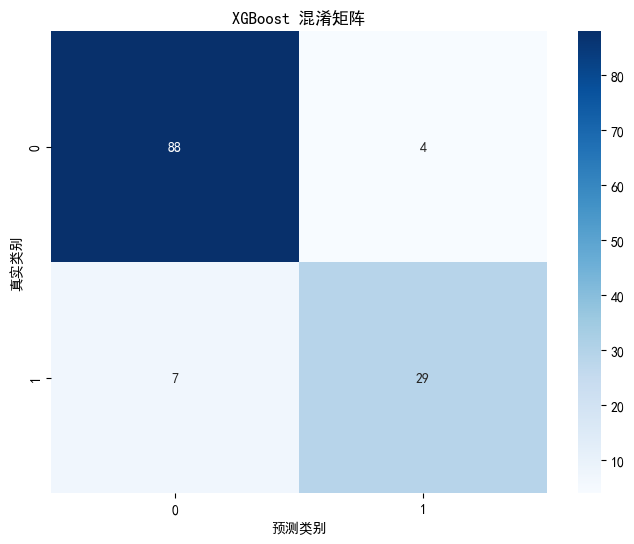

所有分类结果已保存到 预测结果 目录


In [71]:
%matplotlib inline
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
from wordcloud import WordCloud
from sklearn.metrics import silhouette_score, calinski_harabasz_score
import numpy as np
import pandas as pd
from sklearn.svm import SVC
from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
import seaborn as sns
import os

class KmeansClustering():
    def __init__(self, stopwords_path=None):
        self.stopwords = self.load_stopwords(stopwords_path)
        # 增加ngram_range和max_features提升特征表达
        self.vectorizer = CountVectorizer(ngram_range=(1,2), max_features=5000)
        self.transformer = TfidfTransformer()

    def load_stopwords(self, stopwords=None):
        if stopwords:
            with open(stopwords, 'r', encoding='utf-8') as f:
                return [line.strip() for line in f]
        else:
            return []

    def preprocess_data(self, corpus_path):
        corpus = []
        if corpus_path.endswith('.xlsx'):
            df = pd.read_excel(corpus_path, engine='openpyxl')
            texts = df.iloc[:, 0].astype(str).tolist()
            for text in texts:
                corpus.append(' '.join([word for word in jieba.lcut(text.strip()) if word not in self.stopwords]))
        else:
            with open(corpus_path, 'r', encoding='utf-8') as f:
                for line in f:
                    corpus.append(' '.join([word for word in jieba.lcut(line.strip()) if word not in self.stopwords]))
        return corpus

    def get_text_tfidf_matrix(self, corpus):
        tfidf = self.transformer.fit_transform(self.vectorizer.fit_transform(corpus))
        weights = tfidf.toarray()
        return weights

    def plot_clusters(self, weights, labels):
        pca = PCA(n_components=2)
        reduced_weights = pca.fit_transform(weights)
        plt.figure(figsize=(12, 6))
        plt.scatter(reduced_weights[:, 0], reduced_weights[:, 1], c=labels, cmap='viridis', alpha=0.6)
        plt.title("Text Clustering Visualization (PCA Reduced)")
        plt.xlabel("PCA Component 1")
        plt.ylabel("PCA Component 2")
        plt.colorbar(label="Cluster ID")
        plt.show()

    def plot_wordclouds(self, corpus, labels, n_top_words=20):
        clustered_texts = {}
        for idx, label in enumerate(labels):
            if label not in clustered_texts:
                clustered_texts[label] = []
            clustered_texts[label].extend(corpus[idx].split())
        for cluster_id, words in clustered_texts.items():
            wordcloud = WordCloud(width=800, height=400, 
                                background_color='white',
                                font_path='simhei.ttf').generate(' '.join(words))
            plt.figure(figsize=(10, 5))
            plt.imshow(wordcloud, interpolation='bilinear')
            plt.title(f"Cluster {cluster_id} - Top Keywords")
            plt.axis("off")
            plt.show()

    def train_classifiers(self, X, y):
        # 使用StratifiedKFold交叉验证提升评估稳定性
        skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
        svm_accs, xgb_accs, svm_f1s, xgb_f1s = [], [], [], []
        for train_idx, test_idx in skf.split(X, y):
            X_train, X_test = X[train_idx], X[test_idx]
            y_train, y_test = y[train_idx], y[test_idx]
            svm_model = SVC(kernel='linear', C=1.0)
            svm_model.fit(X_train, y_train)
            svm_preds = svm_model.predict(X_test)
            xgb_model = XGBClassifier(use_label_encoder=False, eval_metric='mlogloss')
            xgb_model.fit(X_train, y_train)
            xgb_preds = xgb_model.predict(X_test)
            svm_accs.append(accuracy_score(y_test, svm_preds))
            xgb_accs.append(accuracy_score(y_test, xgb_preds))
            svm_f1s.append(f1_score(y_test, svm_preds, average='weighted'))
            xgb_f1s.append(f1_score(y_test, xgb_preds, average='weighted'))
        print(f"\n分类器性能评估(5折交叉验证均值):")
        print(f"SVM 准确率: {np.mean(svm_accs):.4f} | F1-score: {np.mean(svm_f1s):.4f}")
        print(f"XGBoost 准确率: {np.mean(xgb_accs):.4f} | F1-score: {np.mean(xgb_f1s):.4f}")
        # 用全部数据训练最终模型
        svm_model = SVC(kernel='linear', C=1.0)
        svm_model.fit(X, y)
        xgb_model = XGBClassifier(use_label_encoder=False, eval_metric='mlogloss')
        xgb_model.fit(X, y)
        # 混淆矩阵用最后一折
        self.plot_confusion_matrix(y_test, svm_preds, "SVM 混淆矩阵")
        self.plot_confusion_matrix(y_test, xgb_preds, "XGBoost 混淆矩阵")
        return svm_model, xgb_model

    def plot_confusion_matrix(self, y_true, y_pred, title):
        cm = confusion_matrix(y_true, y_pred)
        plt.figure(figsize=(8,6))
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
                   xticklabels=sorted(set(y_true)), yticklabels=sorted(set(y_true)))
        plt.xlabel('预测类别')
        plt.ylabel('真实类别')
        plt.title(title)
        plt.show()

    def plot_cluster_distribution(self, labels):
        # 聚类分布柱状图
        unique, counts = np.unique(labels, return_counts=True)
        plt.figure(figsize=(10, 5))
        sns.barplot(x=unique, y=counts, palette="viridis")
        plt.title("Cluster Distribution")
        plt.xlabel("Cluster Label")
        plt.ylabel("Number of Samples")
        for i, count in enumerate(counts):
            plt.text(i, count, str(count), ha='center', va='bottom')
        plt.show(block=True)

    def plot_silhouette(self, X, labels):
        # 轮廓系数可视化
        silhouette_vals = silhouette_samples(X, labels)
        n_clusters = len(np.unique(labels))
        y_lower = 10
        plt.figure(figsize=(10, 6))
        for i in range(n_clusters):
            ith_cluster_silhouette_values = silhouette_vals[labels == i]
            ith_cluster_silhouette_values.sort()
            size_cluster_i = ith_cluster_silhouette_values.shape[0]
            y_upper = y_lower + size_cluster_i
            color = plt.cm.viridis(float(i) / n_clusters)
            plt.fill_betweenx(np.arange(y_lower, y_upper),
                              0, ith_cluster_silhouette_values,
                              facecolor=color, edgecolor=color, alpha=0.7)
            plt.text(-0.05, y_lower + 0.5 * size_cluster_i, str(i))
            y_lower = y_upper + 10
        plt.xlabel("Silhouette coefficient values")
        plt.ylabel("Cluster label")
        plt.title("Silhouette Plot for the Clusters")
        plt.axvline(x=np.mean(silhouette_vals), color="red", linestyle="--")
        plt.show(block=True)

    def plot_pca_variance(self, X):
        # PCA累计方差解释率图
        pca = PCA().fit(X)
        plt.figure(figsize=(8, 5))
        plt.plot(np.cumsum(pca.explained_variance_ratio_), marker='o')
        plt.xlabel('Number of Components')
        plt.ylabel('Cumulative Explained Variance')
        plt.title('PCA Cumulative Explained Variance')
        plt.grid(True)
        plt.show(block=True)

    def save_results(self, data, predictions, output_dir="预测结果"):
        os.makedirs(output_dir, exist_ok=True)
        test_data_with_predictions = pd.DataFrame({
            'text': data['text'],
            'true_label': data['label'],
            'predicted_label_svm': predictions['svm'],
            'predicted_label_xgb': predictions['xgb']
        })
        for model in ['svm', 'xgb']:
            for label in test_data_with_predictions[f'predicted_label_{model}'].unique():
                subset = test_data_with_predictions[test_data_with_predictions[f'predicted_label_{model}'] == label]
                file_name = os.path.join(output_dir, f"分类结果_{label}_{model}.xlsx")
                subset.to_excel(file_name, index=False)
        print(f"所有分类结果已保存到 {output_dir} 目录")

    def kmeans(self, corpus_path, n_clusters=5, label_column=None):
        # 读取数据
        if corpus_path.endswith('.xlsx'):
            df = pd.read_excel(corpus_path, engine='openpyxl')
            texts = df.iloc[:, 0].astype(str).tolist()
            corpus = [' '.join([word for word in jieba.lcut(text.strip()) if word not in self.stopwords]) for text in texts]
            labels = df[label_column].values if label_column else None
        else:
            with open(corpus_path, 'r', encoding='utf-8') as f:
                corpus = [' '.join([word for word in jieba.lcut(line.strip()) if word not in self.stopwords]) for line in f]
            labels = None

        weights = self.get_text_tfidf_matrix(corpus)
        # 使用k-means++初始化提升聚类效果
        clf = KMeans(n_clusters=n_clusters, init='k-means++', n_init=20, random_state=42)
        y = clf.fit_predict(weights)

        print(f"\n聚类评估指标（{n_clusters}个簇）")
        print(f"轮廓系数(Silhouette): {silhouette_score(weights, y):.4f}")
        print(f"Calinski-Harabasz指数: {calinski_harabasz_score(weights, y):.4f}")
        unique, counts = np.unique(y, return_counts=True)
        print("簇分布:", dict(zip(unique, counts)))

        self.plot_clusters(weights, y)
        self.plot_wordclouds(corpus, y)

        if labels is not None:
            # 归一化特征提升分类器表现
            from sklearn.preprocessing import StandardScaler

            scaler = StandardScaler()
            weights_scaled = scaler.fit_transform(weights)
            svm_model, xgb_model = self.train_classifiers(weights_scaled, labels)
            predictions = {
                'svm': svm_model.predict(weights_scaled),
                'xgb': xgb_model.predict(weights_scaled)
            }
            data_dict = {
                'text': texts,
                'label': labels
            }
            self.save_results(data_dict, predictions)

        result = {}
        for text_idx, label_idx in enumerate(y):
            if label_idx not in result:
                result[label_idx] = [text_idx]
            else:
                result[label_idx].append(text_idx)
        return result

# 使用示例
if __name__ == "__main__":
    cluster = KmeansClustering(stopwords_path="stop_words.txt")
    clustering_result = cluster.kmeans(
        corpus_path="测试数据.xlsx",
        n_clusters=5,
        label_column="keyword"
    )

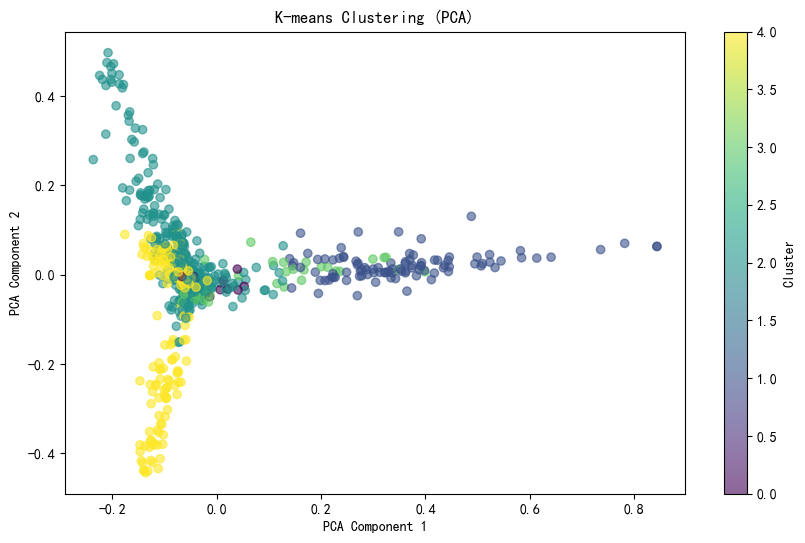

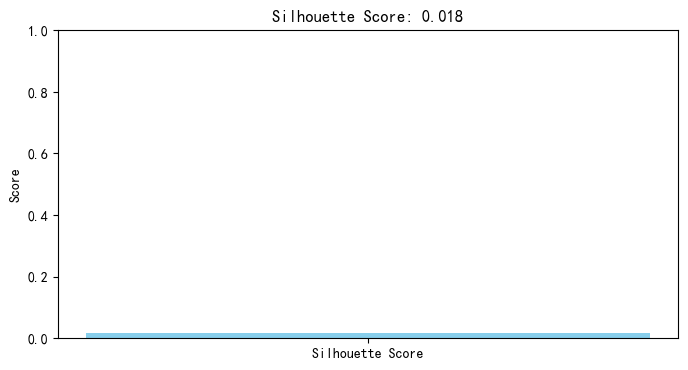

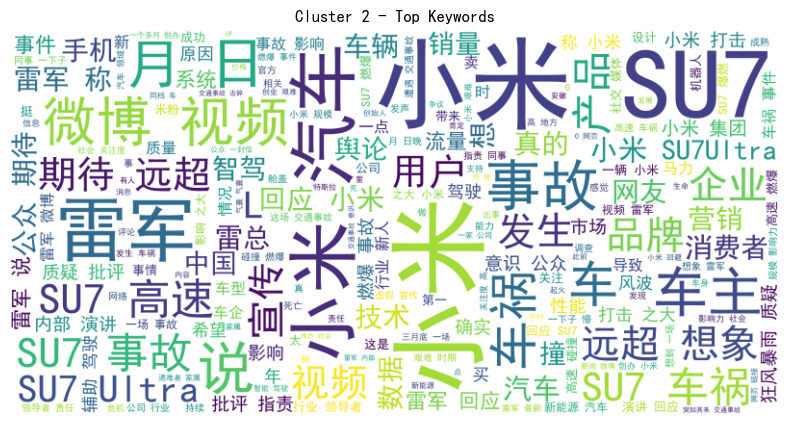

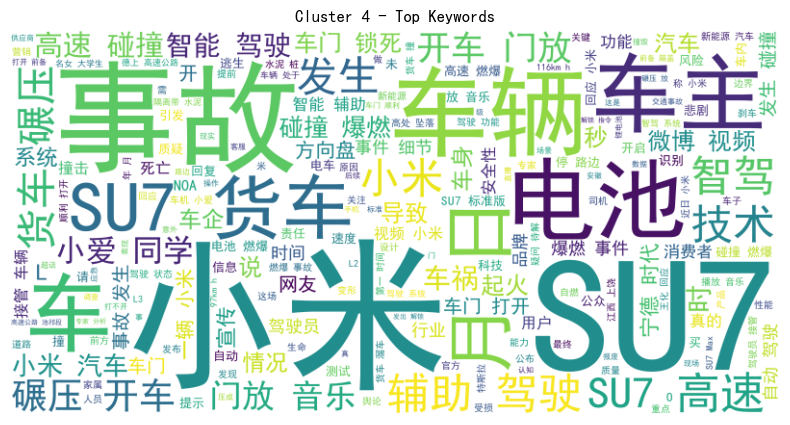

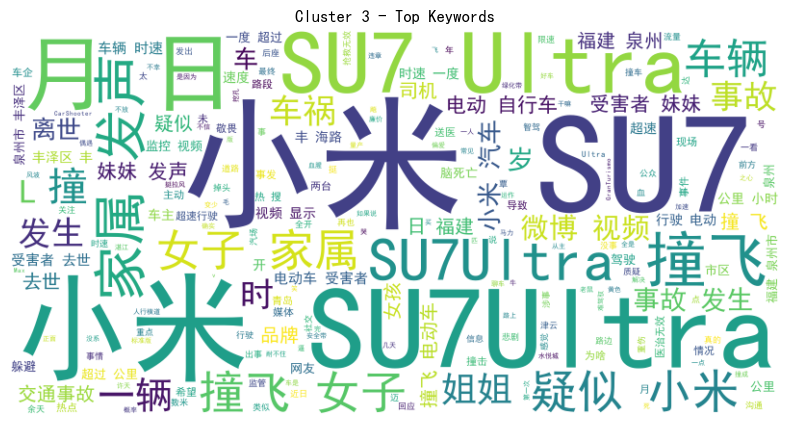

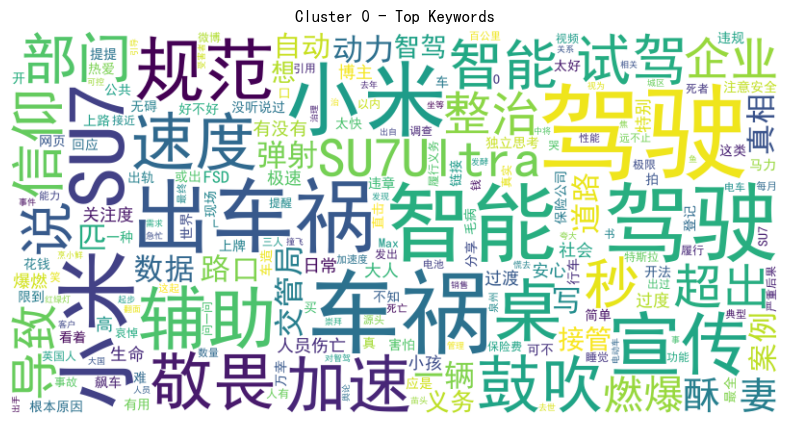

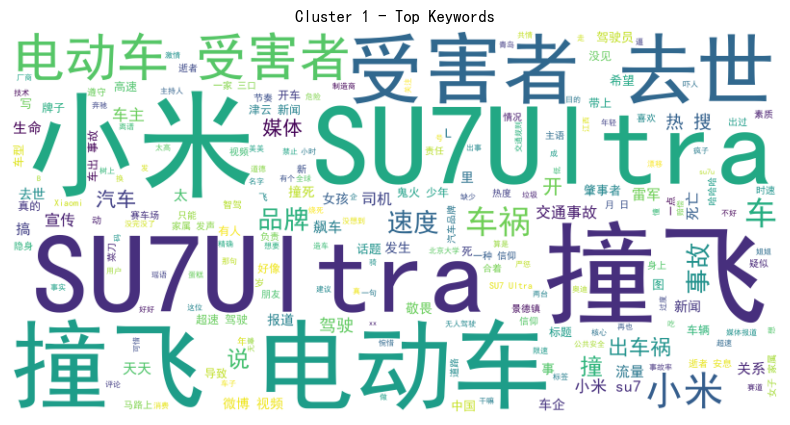

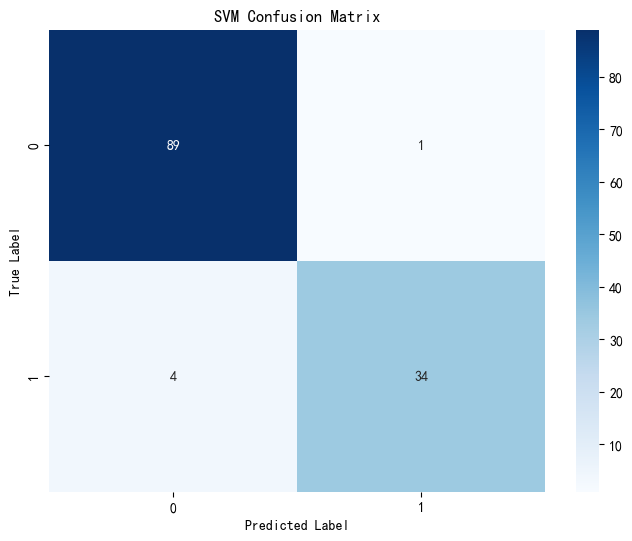

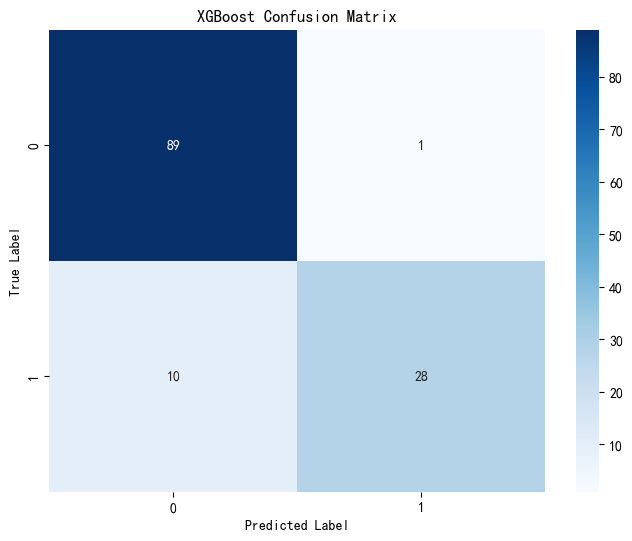

<Figure size 1000x500 with 0 Axes>

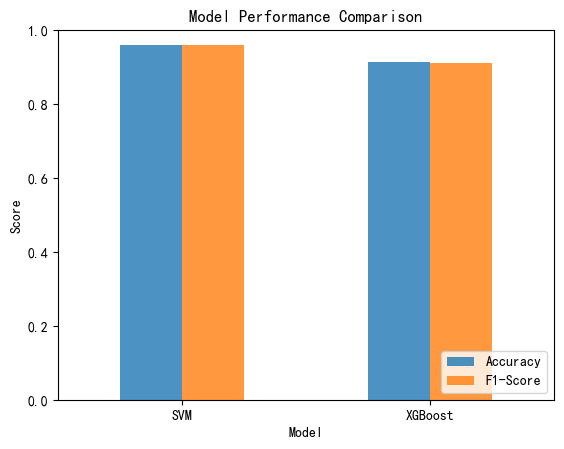

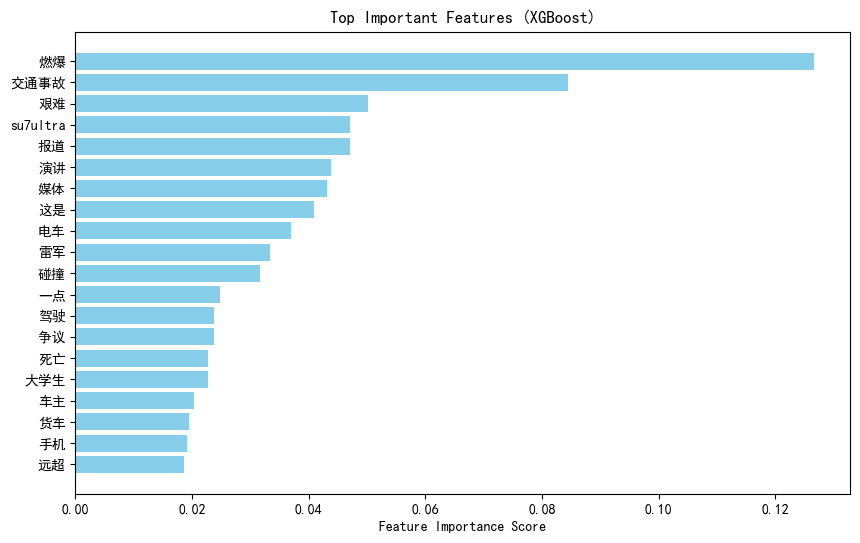

In [11]:
import jieba
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, f1_score, 
                           confusion_matrix, silhouette_score, 
                           calinski_harabasz_score)
from wordcloud import WordCloud
import os

plt.rcParams['font.sans-serif'] = ['SimHei']  # 中文显示
plt.rcParams['axes.unicode_minus'] = False

class TextClusteringVisualization:
    def __init__(self, stopwords_path=None):
        self.stopwords = self.load_stopwords(stopwords_path)
        self.vectorizer = TfidfVectorizer(max_features=5000)
        
    def load_stopwords(self, path):
        if path and os.path.exists(path):
            with open(path, 'r', encoding='utf-8') as f:
                return [line.strip() for line in f]
        return []

    def preprocess(self, texts):
        return [' '.join([word for word in jieba.lcut(text) 
                        if word not in self.stopwords]) for text in texts]

    def fit(self, file_path, n_clusters=5, label_col=None):
        """主流程"""
        if file_path.endswith('.xlsx'):
            df = pd.read_excel(file_path, engine='openpyxl')
            texts = df.iloc[:, 0].astype(str).tolist()
            labels = df[label_col].values if label_col else None
        else:
            with open(file_path, 'r', encoding='utf-8') as f:
                texts = [line.strip() for line in f]
            labels = None
        
        corpus = self.preprocess(texts)
        X = self.vectorizer.fit_transform(corpus)
        
        # K-means聚类
        kmeans = KMeans(n_clusters=n_clusters, random_state=42)
        cluster_labels = kmeans.fit_predict(X)
        
        # 可视化
        self.plot_pca(X, cluster_labels, "K-means Clustering (PCA)")
        self.plot_silhouette(X, cluster_labels)
        self.plot_wordclouds(corpus, cluster_labels)
        
        if labels is not None:
            self.train_and_evaluate(X, labels, corpus)
        
        return cluster_labels

    def plot_pca(self, X, labels, title):
        """PCA降维可视化"""
        pca = PCA(n_components=2)
        reduced = pca.fit_transform(X.toarray())
        
        plt.figure(figsize=(10, 6))
        scatter = plt.scatter(reduced[:, 0], reduced[:, 1], 
                            c=labels, cmap='viridis', alpha=0.6)
        plt.colorbar(scatter, label='Cluster')
        plt.title(title)
        plt.xlabel("PCA Component 1")
        plt.ylabel("PCA Component 2")
        plt.show()

    def plot_silhouette(self, X, labels):
        """轮廓系数可视化"""
        if len(set(labels)) >= 2:
            score = silhouette_score(X, labels)
            plt.figure(figsize=(8, 4))
            plt.bar(['Silhouette Score'], [score], color='skyblue')
            plt.ylim(0, 1)
            plt.title(f"Silhouette Score: {score:.3f}")
            plt.ylabel("Score")
            plt.show()

    def plot_wordclouds(self, corpus, labels, n_top_words=20):
        """生成每个簇的词云图"""
        clustered_texts = {}
        for idx, label in enumerate(labels):
            if label not in clustered_texts:
                clustered_texts[label] = []
            clustered_texts[label].extend(corpus[idx].split())
        
        for cluster_id, words in clustered_texts.items():
            wordcloud = WordCloud(width=800, height=400, 
                                background_color='white',
                                font_path='simhei.ttf').generate(' '.join(words))
            
            plt.figure(figsize=(10, 5))
            plt.imshow(wordcloud, interpolation='bilinear')
            plt.title(f"Cluster {cluster_id} - Top Keywords")
            plt.axis("off")
            plt.show()
            
    def train_and_evaluate(self, X, y, corpus):
        """训练分类器并可视化结果"""
        X_train, X_test, y_train, y_test = train_test_split(
            X, y, test_size=0.2, random_state=42)
        
        # 训练模型
        models = {
            "SVM": SVC(kernel='linear'),
            "XGBoost": XGBClassifier(eval_metric='mlogloss')
        }
        
        results = []
        for name, model in models.items():
            model.fit(X_train, y_train)
            preds = model.predict(X_test)
            acc = accuracy_score(y_test, preds)
            f1 = f1_score(y_test, preds, average='weighted')
            results.append([name, acc, f1])
            
            # 混淆矩阵
            self.plot_confusion_matrix(y_test, preds, f"{name} Confusion Matrix")
        
        # 模型比较
        self.plot_model_comparison(results)
        
        # 特征重要性 (XGBoost)
        if "XGBoost" in models:
            self.plot_feature_importance(models["XGBoost"], corpus)

    def plot_confusion_matrix(self, y_true, y_pred, title):
        """绘制混淆矩阵"""
        cm = confusion_matrix(y_true, y_pred)
        plt.figure(figsize=(8, 6))
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                   xticklabels=np.unique(y_true),
                   yticklabels=np.unique(y_true))
        plt.xlabel('Predicted Label')
        plt.ylabel('True Label')
        plt.title(title)
        plt.show()

    def plot_model_comparison(self, results):
        """模型性能比较"""
        df = pd.DataFrame(results, columns=['Model', 'Accuracy', 'F1-Score'])
        
        plt.figure(figsize=(10, 5))
        df.set_index('Model').plot(kind='bar', rot=0, alpha=0.8)
        plt.title("Model Performance Comparison")
        plt.ylabel("Score")
        plt.ylim(0, 1)
        plt.legend(loc='lower right')
        plt.show()

    def plot_feature_importance(self, model, corpus, top_n=20):
        """XGBoost特征重要性"""
        if hasattr(model, 'feature_importances_'):
            feature_names = self.vectorizer.get_feature_names_out()
            importance = model.feature_importances_
            indices = np.argsort(importance)[-top_n:]
            
            plt.figure(figsize=(10, 6))
            plt.title("Top Important Features (XGBoost)")
            plt.barh(range(top_n), importance[indices], color='skyblue')
            plt.yticks(range(top_n), [feature_names[i] for i in indices])
            plt.xlabel("Feature Importance Score")
            plt.show()


if __name__ == "__main__":
    # 初始化（替换为你的停用词路径）
    visualizer = TextClusteringVisualization(stopwords_path="stop_words.txt")
    
    # 运行分析（替换为你的数据路径）
    # 如果是无监督学习，省略label_col参数
    cluster_labels = visualizer.fit(
        file_path="测试数据.xlsx",  # 支持.txt或.xlsx
        n_clusters=5,
        label_col="keyword"  # 如果有标签列
    )
